# Scheduling two production stages with renewable power

Schedule a steelmaking stage and a finishing stage with separate renewable supplies. Steel inventory decouples the stages. Finished inventory can move output ahead of a month with high demand. A penalty prices shortages when the installed production capacities cannot meet all requests.

This compact port uses four representative blocks in each of the three months. It preserves the legacy conversion ratios, monthly demand levels, capacity limits, and 24-hour renewable profile shapes. The renewable profiles are aggregated and scaled to match the model's illustrative energy units. The shortage penalty is set to 4 per unit so both energy supply cases serve demand.

## Production and renewable inputs

In [1]:
import pandas as pd
from energia import Model, Periods, Process, Resource
from gana import V, inf

monthly_demand = [400, 350, 950]
shortage_penalty = 4
steel_renewables = [8.0, 68.0, 260.0, 52.0]
finish_renewables = [8.0, 106.0, 300.0, 62.0]
blocks_per_month = len(steel_renewables)

## Build the operations and inventory balances

Process conversion equations determine how much steel and energy the finishing stage uses. The inventory equations use those flows and start both inventories at zero. Monthly delivery plus any shortage equals the monthly request.

In [2]:
def schedule(enable_renewables):
    m = Model("renewable_production")
    m.block = Periods()
    m.study = len(monthly_demand) * blocks_per_month * m.block
    m.declare(Resource, ["ore", "steel_energy", "finish_energy", "steel", "steel_feed", "product"])
    _ = m.ore.consume(m.block) >= 0
    _ = m.steel.consume(m.block) == 0
    _ = m.product.consume(m.block) == 0

    # Balance production against transfers into and withdrawals from inventory.
    steel_store = m.steel.release(m.block)
    steel_draw = m.steel_feed.consume(m.block)
    _ = steel_draw >= 0
    _ = steel_store >= 0
    product_store = m.product.release(m.block)
    _ = product_store >= 0

    m.steelmaking = Process(m.steel == -1.1 * m.ore - 1.2 * m.steel_energy)
    m.finishing = Process(m.product == -1.1 * m.steel_feed - 1.2 * m.finish_energy)
    for plant, limit in ((m.steelmaking, 500), (m.finishing, 700)):
        _ = plant.capacity(m.study) == limit / blocks_per_month
        _ = plant.operate(m.block) <= 1

    grid_purchases = 0
    grid_samples = []
    for name, energy, profile in (
        ("steel_solar", m.steel_energy, steel_renewables),
        ("finish_solar", m.finish_energy, finish_renewables),
    ):
        grid = energy.consume(m.block)
        _ = grid >= 0
        grid_purchases += sum(grid.V())
        grid_samples.append(grid)
        supply = Resource()
        setattr(m, f"{name}_supply", supply)
        hourly_limits = (profile if enable_renewables else [0] * blocks_per_month) * len(monthly_demand)
        _ = supply.consume(m.block) <= hourly_limits
        renewable = Process(energy == -supply)
        setattr(m, name, renewable)
        _ = renewable.operate(m.block) >= 0
        renewable.locate()

    m.steelmaking.locate()
    m.finishing.locate()

    size = len(monthly_demand) * blocks_per_month
    m.program.steel_inventory = V(*steel_store.I)
    m.program.product_inventory = V(*steel_store.I)
    m.program.sales = V(*steel_store.I)
    m.program.steel_storage_limit = m.program.steel_inventory <= 800
    m.program.product_storage_limit = m.program.product_inventory <= 800
    steel_stock = list(m.program.steel_inventory)
    product_stock = list(m.program.product_inventory)
    sales = list(m.program.sales)
    for t, (made, drawn, finished) in enumerate(zip(steel_store.V(), steel_draw.V(), product_store.V(), strict=True)):
        previous_steel = steel_stock[t - 1] if t else 0
        previous_product = product_stock[t - 1] if t else 0
        setattr(m.program, f"steel_balance_{t}", steel_stock[t] + drawn == previous_steel + made)
        setattr(m.program, f"product_balance_{t}", product_stock[t] + sales[t] == previous_product + finished)
    m.program.final_steel_inventory = steel_stock[-1] == 0
    m.program.final_product_inventory = product_stock[-1] == 0

    for month, requested in enumerate(monthly_demand):
        start = month * blocks_per_month
        setattr(m.program, f"sales_limit_{month}", sum(sales[start:start + blocks_per_month]) <= requested)
    shortfall = sum(monthly_demand) - sum(sales)
    total_cost = (
        2 * sum(steel_store.V()) + 0.5 * sum(product_store.V())
        + 0.1 * sum(steel_stock + product_stock) + 0.15 * grid_purchases + shortage_penalty * shortfall
    )
    m.program.production_cost = inf(total_cost)
    m.opt()

    sold = sum(m.program.sales.output(aslist=True))
    assert size == len(sales) and sold <= sum(monthly_demand) + 1e-6
    unmet = sum(monthly_demand) - sold
    assert all(stock <= 800 + 1e-6 for stock in m.program.steel_inventory.output(aslist=True))
    return {
        "Total cost": m.program.active_objective.X,
        "Grid purchases": sum(sum(grid.output(aslist=True)) for grid in grid_samples),
        "Finished goods sold": sold,
        "Unmet demand": unmet,
    }

## Compare with and without renewable supply

In [3]:
grid_only = schedule(enable_renewables=False)
with_renewables = schedule(enable_renewables=True)
assert with_renewables["Total cost"] <= grid_only["Total cost"] + 1e-6
assert with_renewables["Grid purchases"] < grid_only["Grid purchases"]
pd.DataFrame([grid_only, with_renewables], index=["Grid only", "Grid and renewables"]).round(2)

,Total cost,Grid purchases,Finished goods sold,Unmet demand
Grid only,5568.64,3436.36,1363.64,336.36
Grid and renewables,5297.66,1574.18,1363.64,336.36


## Production service with renewable power

Stack sales and unmet demand so each bar recovers the same total requested
quantity. The second panel compares purchased grid electricity; it is a
modeled block total, with no unprovided duration factor. These comparisons
use the two existing solves and keep production and electricity separate.

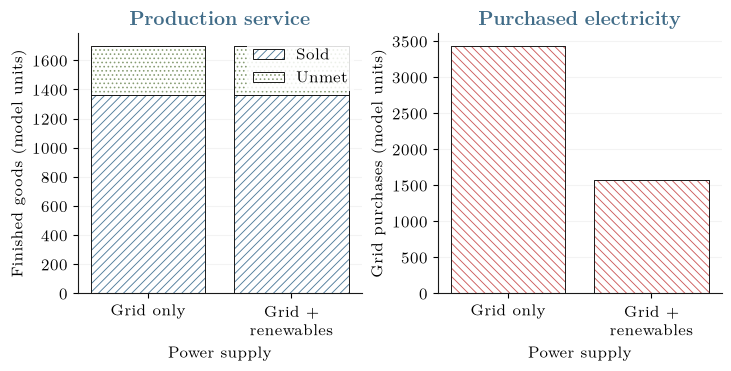

In [4]:
from gana.plotting import bar, row, stacked

cases = pd.DataFrame(
    [grid_only, with_renewables], index=["Grid only", "Grid +\nrenewables"]
)
options = cases.index.tolist()
deliveries = (
    stacked(cases["Finished goods sold"].tolist(), x=options, label="Sold")
    + stacked(cases["Unmet demand"].tolist(), x=options, label="Unmet")
).with_options(title="Production service", ylabel="Finished goods (model units)")
grid_use = bar(
    cases["Grid purchases"].tolist(),
    x=options,
    title="Purchased electricity",
    ylabel="Grid purchases (model units)",
)
production_plot = row(
    deliveries, grid_use, fig_size=(7.2, 3.6), xlabel="Power supply", ylim=(0, None)
)
production_plot.show();